# Bài thực hành Word Embedding tiếng Việt

**Bài 1:** Tạo mô hình word embedding bằng Word2Vec Skip-gram với negative sampling.  
**Bài 2:** Tìm 10 cặp từ tương đồng bằng cosine, rồi giảm vector từ 100 chiều xuống 2D và 3D.

Lời giải dựa trên tài liệu **3. Semantics-WordEmbedding.pdf**, TS. Vương Thị Hải Yến, Trường Đại học Công nghệ - ĐHQG Hà Nội: giả thuyết phân bố (tr. 21), cosine (tr. 26), Word2Vec (tr. 38, 49-50), negative sampling (tr. 59-61), PCA và t-SNE (tr. 69). Tài liệu là cơ sở lý thuyết; ngữ liệu huấn luyện là Wikipedia tiếng Việt.

Notebook chứa toàn bộ mã cần chạy, kèm kết quả đã thực thi. Có mô hình lưu sẵn thì mặc định nạp lại; đặt `RETRAIN=True` để huấn luyện mới.

## 1. Môi trường

Dùng Python 3.12. Ô sau cài các gói cần thiết nếu môi trường chưa có. Lần chạy đã lưu dùng đúng các phiên bản trong `requirements.txt`. Với Colab, có thể cần khởi động lại runtime nếu vừa thay NumPy hoặc SciPy.

In [1]:
import importlib.util
import subprocess
import sys

packages = ["gensim==4.4.0", "numpy==2.5.4", "scipy==1.18.1",
            "scikit-learn==1.6.1", "matplotlib==3.11.2", "pyvi==0.1.1",
            "sklearn-crfsuite==0.5.0", "python-crfsuite==0.9.12"]
needed = ["gensim", "sklearn", "matplotlib", "pyvi"]
if any(importlib.util.find_spec(name) is None for name in needed):
    subprocess.check_call([sys.executable, "-m", "pip", "install", *packages])
print("Python:", sys.version.split()[0])

Python: 3.12.14


In [2]:
"""Hai bài thực hành Word2Vec tiếng Việt. Python 3.12; xem README.md."""

import argparse
import csv
import gzip
import hashlib
import json
import re
import sys
import time
import unicodedata
import urllib.parse
import urllib.request
import zlib
from pathlib import Path

import numpy as np
from gensim.models import Word2Vec
from gensim.models.callbacks import CallbackAny2Vec
from gensim.models.word2vec import LineSentence
from pyvi import ViTokenizer

SEED = 42
DATASET = "wikimedia/wikipedia"
CONFIG = "20231101.vi"
N_ARTICLES = 2000
# Chọn trước khi huấn luyện; từ ghép dùng dấu gạch dưới theo Pyvi.
QUERY_WORDS = ["học_sinh", "giáo_viên", "bác_sĩ", "bệnh_viện", "máy_tính",
               "điện_thoại", "ô_tô", "bóng_đá", "âm_nhạc", "toán_học"]
PARAMETERS = dict(vector_size=100, window=5, min_count=5, sg=1,
                  negative=10, hs=0, sample=1e-3, ns_exponent=0.75,
                  alpha=0.025, min_alpha=0.0001, epochs=15,
                  workers=1, seed=SEED, sorted_vocab=1, shrink_windows=True)




In [3]:
# Trên Colab: giải nén gói vào /content/word_embedding_vi để dùng cache.
if Path("/content").exists():
    candidates = [Path("/content/NLP-Word-Embedding"), Path("/content/word_embedding_vi")]
    ROOT = next((p for p in candidates if (p / "models/word2vec_vi.model").exists()), candidates[1])
else:
    ROOT = Path.cwd()
ROOT.mkdir(parents=True, exist_ok=True)
RETRAIN = False
print("Thư mục làm việc:", ROOT)
print("10 từ truy vấn cố định:", QUERY_WORDS)

Thư mục làm việc: word_embedding_vi
10 từ truy vấn cố định: ['học_sinh', 'giáo_viên', 'bác_sĩ', 'bệnh_viện', 'máy_tính', 'điện_thoại', 'ô_tô', 'bóng_đá', 'âm_nhạc', 'toán_học']


## 2. Bài 1 - Dữ liệu và tiền xử lý

Nguồn: [wikimedia/wikipedia](https://huggingface.co/datasets/wikimedia/wikipedia), cấu hình `20231101.vi`, split `train`. Lấy đúng 2.000 bài đầu, hàng 0-1999. Đây là mẫu thuận tiện để thực hành, không đại diện toàn bộ ngôn ngữ.

Quy trình:
1. Chuẩn hóa Unicode NFC và loại URL.
2. Tách câu gần đúng bằng dấu câu và xuống dòng.
3. Tách từ bằng [Pyvi](https://github.com/trungtv/pyvi); sau đó chuyển chữ thường, giữ dấu tiếng Việt.
4. Giữ token chỉ chứa chữ và dấu `_` nối các thành tố; loại số, dấu câu và câu dưới 3 token.
5. Loại văn bản trùng; giữ từ chức năng để bảo toàn ngữ cảnh. Word2Vec giảm lấy mẫu từ rất phổ biến bằng `sample=1e-3`.

Dấu cách tiếng Việt thường phân tách âm tiết. Vì vậy `máy tính` cần được biểu diễn bằng token `máy_tính` thay vì mặc định coi hai âm tiết là hai từ độc lập. Bộ tách từ vẫn có thể sai. Văn bản và URL từng bài được lưu để truy nguyên; SHA-256 kiểm tra dữ liệu.

In [4]:
def stable_hash(value):
    """Hash cố định, không phụ thuộc PYTHONHASHSEED của tiến trình."""
    return zlib.crc32(value.encode("utf-8"))


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def dump_json(path, data):
    Path(path).write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")


def download_corpus(root, n_articles=N_ARTICLES):
    """Lấy các hàng 0..1999, lưu văn bản cùng URL để truy nguyên nguồn."""
    root = Path(root)
    data_dir = root / "data"
    cache_dir = root.parent / "work/wiki_download_cache"
    cache_dir.mkdir(parents=True, exist_ok=True)
    output = data_dir / "wiki_vi_2000.jsonl.gz"
    metadata = data_dir / "download_metadata.json"
    if output.exists() and metadata.exists():
        saved = json.loads(metadata.read_text(encoding="utf-8"))
        if saved["n_articles"] != n_articles or sha256(output) != saved["sha256"]:
            raise ValueError("Dữ liệu cache không khớp cấu hình hoặc checksum.")
        return output
    rows = []
    for offset in range(0, n_articles, 100):
        length = min(100, n_articles - offset)
        cached = cache_dir / f"page_{offset:05d}.json"
        params = urllib.parse.urlencode(dict(dataset=DATASET, config=CONFIG,
                                             split="train", offset=offset, length=length))
        url = "https://datasets-server.huggingface.co/rows?" + params
        if cached.exists():
            page = json.loads(cached.read_text(encoding="utf-8"))
        else:
            for attempt in range(4):
                try:
                    req = urllib.request.Request(url, headers={"User-Agent": "WordEmbeddingCourse/1.0"})
                    with urllib.request.urlopen(req, timeout=120) as response:
                        page = json.load(response)
                    break
                except Exception:
                    if attempt == 3:
                        raise
                    time.sleep(2 ** attempt)
            dump_json(cached, page)
        if len(page["rows"]) != length:
            raise ValueError(f"Thiếu hàng dữ liệu tại offset={offset}.")
        for item in page["rows"]:
            if item.get("truncated_cells"):
                raise ValueError("API trả văn bản bị cắt; không dùng để huấn luyện.")
            rows.append(dict(row_index=item["row_idx"], **item["row"]))
        print(f"Đã tải {len(rows)}/{n_articles} bài", flush=True)
    assert [r["row_index"] for r in rows] == list(range(n_articles))
    with gzip.open(output, "wt", encoding="utf-8", newline="\n") as f:
        for row in rows:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")
    dump_json(metadata, dict(dataset=DATASET, config=CONFIG, split="train",
                            row_start=0, row_end=n_articles-1, n_articles=len(rows),
                            selection="First 2000 rows; convenience sample, not random",
                            source="https://huggingface.co/datasets/wikimedia/wikipedia",
                            license="CC BY-SA 3.0 / GFDL, per dataset card",
                            sha256=sha256(output)))
    return output


def tokenize_text(text):
    """Giữ dấu tiếng Việt; tách câu gần đúng, tách từ rồi chuyển chữ thường."""
    text = unicodedata.normalize("NFC", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    for sentence in re.split(r"[.!?;\n]+", text):
        sentence = sentence.strip()
        if not sentence:
            continue
        tokens = ViTokenizer.tokenize(sentence).lower().split()
        tokens = [w for w in tokens if all(part.isalpha() for part in w.split("_"))]
        if len(tokens) >= 3:
            yield tokens


def prepare_corpus(root):
    root = Path(root)
    raw = root / "data/wiki_vi_2000.jsonl.gz"
    corpus = root / "data/corpus_tokenized.txt"
    info_path = root / "data/corpus_metadata.json"
    if corpus.exists() and info_path.exists():
        info = json.loads(info_path.read_text(encoding="utf-8"))
        if info["raw_sha256"] == sha256(raw) and info["corpus_sha256"] == sha256(corpus):
            return corpus, info
        raise ValueError("Corpus hoặc dữ liệu nguồn đã thay đổi.")
    started = time.perf_counter()
    n_docs = n_sentences = n_tokens = duplicates = 0
    seen = set()
    with gzip.open(raw, "rt", encoding="utf-8") as f, corpus.open("w", encoding="utf-8", newline="\n") as out:
        for index, line in enumerate(f, 1):
            record = json.loads(line)
            text = unicodedata.normalize("NFC", record["text"])
            key = hashlib.sha256(text.encode("utf-8")).hexdigest()
            if key in seen:
                duplicates += 1
                continue
            seen.add(key)
            contributed = False
            for tokens in tokenize_text(text):
                out.write(" ".join(tokens) + "\n")
                n_sentences += 1
                n_tokens += len(tokens)
                contributed = True
            n_docs += int(contributed)
            if index % 100 == 0:
                print(f"Tách từ: {index} bài; {n_tokens:,} token", flush=True)
    info = dict(articles_used=n_docs, duplicates_removed=duplicates,
                sentences=n_sentences, tokens_before_min_count=n_tokens,
                raw_sha256=sha256(raw), corpus_sha256=sha256(corpus),
                preprocessing_seconds=round(time.perf_counter()-started, 2),
                tokenizer="pyvi.ViTokenizer 0.1.1", normalization="NFC; lowercase after segmentation",
                sentence_split="Approximate regex: punctuation and newline",
                filtering="URLs, numbers and punctuation removed; at least 3 tokens per sentence",
                stopwords="Kept; frequent-word subsampling handled by Word2Vec")
    dump_json(info_path, info)
    return corpus, info

In [5]:
example = "Sinh viên sử dụng máy tính. Giáo viên giảng dạy tại trường học."
print(list(tokenize_text(example)))
raw_path = download_corpus(ROOT)
corpus_path, corpus_info = prepare_corpus(ROOT)
print(json.dumps(corpus_info, ensure_ascii=False, indent=2))

[['sinh_viên', 'sử_dụng', 'máy_tính'], ['giáo_viên', 'giảng_dạy', 'tại', 'trường_học']]
{
  "articles_used": 1999,
  "duplicates_removed": 0,
  "sentences": 214886,
  "tokens_before_min_count": 3805712,
  "raw_sha256": "0ccb06274bee748bbce5646b05b7917f706c2e1d7a179c9a1c962bbaecdb3a23",
  "corpus_sha256": "a04e8b0d97cd30bf1f405412fd907bfea8c4535e62d424039b709a9552812220",
  "preprocessing_seconds": 49.5,
  "tokenizer": "pyvi.ViTokenizer 0.1.1",
  "normalization": "NFC; lowercase after segmentation",
  "sentence_split": "Approximate regex: punctuation and newline",
  "filtering": "URLs, numbers and punctuation removed; at least 3 tokens per sentence",
  "stopwords": "Kept; frequent-word subsampling handled by Word2Vec"
}


## 3. Bài 1 - Mô hình Word2Vec

Theo giả thuyết phân bố, các từ có ngữ cảnh giống nhau thường có nghĩa gần nhau. Skip-gram dùng từ trung tâm $c$ để dự đoán từ ngữ cảnh $o$ trong cửa sổ.

Với negative sampling, loss cho một cặp dương $(c,o)$ là:

$$\mathcal{L}(c,o)=-\log\sigma(u_o^Tv_c)-\sum_{i=1}^{K}\log\sigma(-u_{n_i}^Tv_c).$$

$v_c$ là vector đầu vào; $u_o$ là vector đầu ra; $n_i$ là từ âm lấy từ phân phối nhiễu; $\sigma$ là sigmoid. Bài dùng $K=10$, phân phối lấy mẫu tỉ lệ với tần suất mũ $0.75$.

Mô hình học hai ma trận $W_{in},W_{out}\in\mathbb{R}^{|V|\times100}$. Lấy các hàng của $W_{in}$ làm embedding qua `model.wv` (phù hợp cách lấy vector ở trang 49). Khởi tạo ngẫu nhiên, **không dùng embedding huấn luyện sẵn**. Pyvi chỉ cung cấp bộ tách từ.

| Tham số | Giá trị | Ý nghĩa |
|---|---:|---|
| `sg` | 1 | Skip-gram |
| `vector_size` | 100 | Số chiều embedding |
| `window` | 5 | Bán kính cửa sổ tối đa; Gensim thu nhỏ ngẫu nhiên khi huấn luyện |
| `min_count` | 5 | Bỏ token xuất hiện ít hơn 5 lần |
| `negative`, `hs` | 10, 0 | Dùng 10 mẫu âm, không dùng hierarchical softmax |
| `epochs` | 15 | Số lượt duyệt corpus |
| `sample` | 0.001 | Giảm lấy mẫu token rất phổ biến |
| `workers`, `seed` | 1, 42 | Hạn chế dao động giữa các lần chạy |

Hàm băm CRC32 cố định được dùng lúc khởi tạo. Đây là học biểu diễn không giám sát; các từ truy vấn vẫn có mặt trong corpus. Không coi kết quả truy vấn là đánh giá trên tập kiểm thử độc lập.

In [6]:
class EpochLogger(CallbackAny2Vec):
    def __init__(self):
        self.epoch = 0
        self.started = time.perf_counter()

    def on_epoch_end(self, model):
        self.epoch += 1
        print(f"Epoch {self.epoch}/{model.epochs}; {time.perf_counter()-self.started:.1f}s", flush=True)


def train_model(root):
    root = Path(root)
    corpus, corpus_info = prepare_corpus(root)
    np.random.seed(SEED)
    started = time.perf_counter()
    sentences = LineSentence(str(corpus))
    model = Word2Vec(**PARAMETERS, hashfxn=stable_hash)
    model.build_vocab(sentences)
    print(f"Từ vựng: {len(model.wv):,}; kích thước vector: {model.vector_size}", flush=True)
    effective, raw = model.train(sentences, total_examples=model.corpus_count,
                                epochs=model.epochs, callbacks=[EpochLogger()])
    model_dir = root / "models"
    model_dir.mkdir(exist_ok=True)
    # Hash không còn cần sau khởi tạo; dùng hàm chuẩn giúp model nạp độc lập.
    model.hashfxn = hash
    model.save(str(model_dir / "word2vec_vi.model"), separately=[])
    model.wv.save(str(model_dir / "word_vectors_vi.kv"), separately=[])
    from importlib.metadata import version
    info = dict(parameters=PARAMETERS, initialization_hash="CRC32 UTF-8",
                vocabulary_size=len(model.wv), vector_shape=list(model.wv.vectors.shape),
                corpus=corpus_info, effective_training_tokens=effective,
                raw_training_tokens=raw, training_seconds=round(model.total_train_time, 2),
                versions=dict(python=sys.version.split()[0], gensim=version("gensim"),
                              numpy=np.__version__, scipy=version("scipy"),
                              sklearn=version("scikit-learn"), matplotlib=version("matplotlib"), pyvi="0.1.1"))
    dump_json(root / "training_metadata.json", info)
    return model, info

In [7]:
model_path = ROOT / "models/word2vec_vi.model"
if RETRAIN or not model_path.exists():
    model, training_info = train_model(ROOT)
else:
    model = Word2Vec.load(str(model_path))
    training_info = json.loads((ROOT / "training_metadata.json").read_text(encoding="utf-8"))
    print("Đã nạp mô hình của lần huấn luyện được lưu.")
print("Kích thước ma trận embedding:", model.wv.vectors.shape)
print("Thời gian huấn luyện đã ghi (giây):", training_info["training_seconds"])
print("Phiên bản:", training_info["versions"])
print("10 phần tử đầu vector máy_tính:", model.wv["máy_tính"][:10])

Đã nạp mô hình của lần huấn luyện được lưu.
Kích thước ma trận embedding: (23788, 100)
Thời gian huấn luyện đã ghi (giây): 281.44
Phiên bản: {'python': '3.12.14', 'gensim': '4.4.0', 'numpy': '2.5.4', 'scipy': '1.18.1', 'sklearn': '1.6.1', 'matplotlib': '3.11.2', 'pyvi': '0.1.1'}
10 phần tử đầu vector máy_tính: [ 0.17918669 -0.40464705 -0.08785702  0.5960179   0.05596058  0.6859392
  0.20420049 -0.5250276  -0.24026471 -0.15398373]


## 4. Bài 2 - Tìm 10 cặp tương đồng

Đo cosine trên **vector gốc 100 chiều**:

$$\mathrm{cosine}(v,w)=\frac{v^Tw}{\lVert v\rVert_2\lVert w\rVert_2}.$$

Cosine nằm trong $[-1,1]$. Giá trị càng gần 1 cho biết hai vector càng cùng hướng; đây không phải xác suất hay độ chính xác.

Chọn trước 10 từ truy vấn ở đầu notebook. Với mỗi từ, tìm láng giềng gần nhất trên **toàn bộ từ vựng mô hình**, loại chính nó và cặp đảo chiều đã xuất hiện. Không dùng ngưỡng để sửa số liệu. Đây là 10 cặp theo truy vấn, **không phải top 10 cặp toàn cục**. `neighbor_rank` cho biết hạng của láng giềng thực tế.

In [8]:
def find_pairs(model, queries=QUERY_WORDS):
    """Láng giềng gần nhất theo cosine, tìm trên toàn bộ từ vựng của mô hình."""
    pairs = []
    seen = set()
    for query in queries:
        if query not in model.wv:
            raise KeyError(f"Từ truy vấn ngoài từ vựng: {query}")
        # topn=20 cho phép bỏ cặp đảo chiều đã xuất hiện, nếu có.
        for rank, (neighbor, score) in enumerate(model.wv.most_similar(query, topn=20), 1):
            key = tuple(sorted([query, neighbor]))
            if key not in seen:
                seen.add(key)
                pairs.append(dict(word1=query, word2=neighbor, cosine=float(score),
                                  neighbor_rank=rank,
                                  count1=int(model.wv.get_vecattr(query, "count")),
                                  count2=int(model.wv.get_vecattr(neighbor, "count"))))
                break
    if len(pairs) != 10:
        raise ValueError("Phải tìm đủ 10 cặp không trùng.")
    return pairs

In [9]:
pairs = find_pairs(model)
from IPython.display import HTML, display, Image
from html import escape
table = "<table><tr><th>STT</th><th>Từ truy vấn</th><th>Láng giềng</th><th>Cosine 100D</th><th>Hạng</th><th>Tần suất</th></tr>"
for i, pair in enumerate(pairs, 1):
    table += (f"<tr><td>{i}</td><td>{escape(pair['word1'])}</td><td>{escape(pair['word2'])}</td>"
              f"<td>{pair['cosine']:.4f}</td><td>{pair['neighbor_rank']}</td>"
              f"<td>{pair['count1']} / {pair['count2']}</td></tr>")
display(HTML(table + "</table>"))

STT,Từ truy vấn,Láng giềng,Cosine 100D,Hạng,Tần suất
1,học_sinh,sinh_viên,0.7978,1,265 / 368
2,giáo_viên,dạy,0.6725,1,85 / 409
3,bác_sĩ,y_sĩ,0.7116,1,259 / 12
4,bệnh_viện,đa_khoa,0.8078,1,441 / 59
5,máy_tính,phần_cứng,0.7938,1,1636 / 194
6,điện_thoại,email,0.7226,1,167 / 83
7,ô_tô,xe_hơi,0.7752,1,236 / 70
8,bóng_đá,đội_tuyển,0.8137,1,546 / 136
9,âm_nhạc,vũ_đạo,0.7241,1,535 / 17
10,toán_học,giải_tích,0.7319,1,1028 / 79


## 5. Bài 2 - Giảm chiều

Lấy tập từ không trùng thuộc 10 cặp. Chuẩn hóa L2 từng vector, tạo ma trận $X$. Chuẩn hóa này giúp xem cấu trúc theo hướng vector, phù hợp với cosine.

**PCA:** Đưa từng cột về trung bình 0, tìm các hướng có phương sai lớn nhất rồi chiếu:

$$Z_k=(X-\mu)U_k,\qquad k\in\{2,3\}.$$

Fit một PCA 3 chiều. Hai cột đầu là PCA 2D; ba cột là PCA 3D. Tỷ lệ phương sai được tính trên tập từ đang hiển thị, không phải toàn bộ từ vựng.

**t-SNE:** Chiếu sang 2D với `perplexity=5`, `random_state=42`, 1.500 vòng lặp và khởi tạo PCA. Perplexity nhỏ hơn số điểm. Dùng khoảng cách Euclidean trên vector đã chuẩn hóa; khi đó khoảng cách bình phương bằng $2(1-\mathrm{cosine})$.

Cả hai phương pháp đều mất thông tin. t-SNE ưu tiên quan hệ cục bộ; khoảng cách giữa các cụm và kích thước cụm trên hình không phải phép đo ngữ nghĩa đáng tin cậy.

In [10]:
def reduce_dimensions(model, pairs):
    from sklearn.decomposition import PCA
    from sklearn.manifold import TSNE
    words = list(dict.fromkeys(w for p in pairs for w in [p["word1"], p["word2"]]))
    vectors = np.vstack([model.wv[w] for w in words])
    normalized = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)
    # Fit một PCA 3 chiều; hai cột đầu chính là phép chiếu PCA 2 chiều.
    pca = PCA(n_components=3, svd_solver="full")
    pca3 = pca.fit_transform(normalized)
    perplexity = min(5.0, len(words)-1.0)
    tsne2 = TSNE(n_components=2, perplexity=perplexity, init="pca",
                 learning_rate="auto", max_iter=1500, random_state=SEED,
                 metric="euclidean").fit_transform(normalized)
    return dict(words=words, original_vectors=vectors, normalized_vectors=normalized,
                pca2=pca3[:, :2], pca3=pca3, tsne2=tsne2,
                explained_variance_ratio=pca.explained_variance_ratio_,
                tsne_perplexity=perplexity, pca=pca)


def make_plots(root, pairs, reduced):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D
    plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                         "axes.spines.top": False, "axes.spines.right": False})
    output = Path(root) / "figures"
    output.mkdir(exist_ok=True)
    words = reduced["words"]
    lookup = {w:i for i,w in enumerate(words)}
    colors = list(plt.colormaps["tab10"].colors)
    ev = reduced["explained_variance_ratio"]
    legend_labels = [f'{i+1:02d}. {p["word1"].replace("_", " ")} / {p["word2"].replace("_", " ")}'
                     for i,p in enumerate(pairs)]
    handles = [Line2D([0],[0],color=colors[i],marker="o",lw=1.5,label=label)
               for i,label in enumerate(legend_labels)]
    for key, title in [("pca2", f"PCA 2D | Giữ {sum(ev[:2]):.1%} phương sai"),
                       ("tsne2", "t-SNE 2D | Perplexity = 5, seed = 42")]:
        points = reduced[key]
        fig, ax = plt.subplots(figsize=(12.5, 8))
        fig.subplots_adjust(left=.09,right=.96,top=.85,bottom=.34)
        fig.suptitle(title, x=.08, y=.96, ha="left", fontsize=20, weight="bold", color="#18344d")
        fig.text(.08,.90,"10 cặp truy vấn và láng giềng | Word2Vec tiếng Việt, 100 chiều",fontsize=11,color="#526273")
        for i,pair in enumerate(pairs):
            ids = [lookup[pair["word1"]],lookup[pair["word2"]]]
            xy = points[ids]
            ax.plot(xy[:,0],xy[:,1],color=colors[i],alpha=.65,lw=1.4)
            ax.scatter(xy[:,0],xy[:,1],color=colors[i],s=60,zorder=3)
            # Nhãn số giữ hình rõ; bảng chú giải xác định từng cặp.
            for j,index in enumerate(ids):
                other = xy[1-j]
                dx = 6 if points[index,0] >= other[0] else -6
                dy = 10 if points[index,1] >= other[1] else -15
                if key == "pca2" and i == 0:
                    dx,dy = (-9,-15) if j == 0 else (-10,12)
                if key == "pca2" and i == 5 and j == 0:
                    dx,dy = 12,16
                ax.annotate(f"{i+1}{'a' if j==0 else 'b'}", points[index],
                            xytext=(dx,dy),textcoords="offset points", fontsize=10,
                            ha="left" if dx > 0 else "right",
                            bbox=dict(boxstyle="round,pad=.13",fc="white",ec="none",alpha=.8))
        ax.set_xlabel(f"PC1 ({ev[0]:.1%})" if key=="pca2" else "t-SNE 1")
        ax.set_ylabel(f"PC2 ({ev[1]:.1%})" if key=="pca2" else "t-SNE 2")
        ax.grid(alpha=.2)
        ax.margins(.12)
        fig.legend(handles=handles,loc="lower left",bbox_to_anchor=(.07,.065),ncol=2,
                   fontsize=10,frameon=False,columnspacing=3,handlelength=1.7,labelspacing=.65)
        fig.text(.08,.025,"a: từ truy vấn; b: láng giềng. Tính cosine trên 100 chiều, không trên tọa độ hình.",
                 fontsize=9,color="#526273")
        fig.savefig(output / f"{key}.png",dpi=180)
        plt.close(fig)
    fig = plt.figure(figsize=(12.5,8.5))
    ax=fig.add_axes([.02,.26,.96,.64],projection="3d")
    points=reduced["pca3"]
    for i,pair in enumerate(pairs):
        ids=[lookup[pair["word1"]],lookup[pair["word2"]]]
        xyz=points[ids]
        ax.plot(xyz[:,0],xyz[:,1],xyz[:,2],color=colors[i],lw=1.5)
        ax.scatter(xyz[:,0],xyz[:,1],xyz[:,2],color=colors[i],s=50,depthshade=False)
    ax.set_xlabel(f"PC1 ({ev[0]:.1%})",labelpad=8)
    ax.set_ylabel(f"PC2 ({ev[1]:.1%})",labelpad=8)
    ax.set_zlabel(f"PC3 ({ev[2]:.1%})",labelpad=8)
    ax.view_init(elev=22,azim=38)
    from mpl_toolkits.mplot3d import proj3d
    for i,pair in enumerate(pairs):
        ids=[lookup[pair["word1"]],lookup[pair["word2"]]]
        projected=[proj3d.proj_transform(*points[index],ax.get_proj()) for index in ids]
        for j,(x,y,z) in enumerate(projected):
            other=projected[1-j]
            dx=7 if x >= other[0] else -7
            dy=9 if y >= other[1] else -12
            if (i,j) == (5,0):
                dx,dy=25,5
            elif (i,j) == (6,0):
                dx,dy=22,-7
            elif (i,j) == (8,0):
                dx,dy=-22,-8
            ax.annotate(f"{i+1}{'a' if j==0 else 'b'}",(x,y),xytext=(dx,dy),
                        textcoords="offset points",ha="left" if dx > 0 else "right",
                        fontsize=10,bbox=dict(boxstyle="round,pad=.12",fc="white",ec="none",alpha=.8))
    fig.suptitle(f"PCA 3D | Giữ {sum(ev):.1%} phương sai",x=.08,y=.96,ha="left",
                 fontsize=20,weight="bold",color="#18344d")
    fig.legend(handles=handles,loc="lower left",bbox_to_anchor=(.07,.045),ncol=2,
               fontsize=10,frameon=False,columnspacing=3,handlelength=1.7,labelspacing=.65)
    fig.text(.08,.018,"a: từ truy vấn; b: láng giềng. Phép chiếu làm mất một phần thông tin.",fontsize=9,color="#526273")
    fig.savefig(output / "pca3.png",dpi=180)
    plt.close(fig)


def analyze(root, model=None):
    root=Path(root)
    if model is None:
        model=Word2Vec.load(str(root / "models/word2vec_vi.model"))
    pairs=find_pairs(model)
    reduced=reduce_dimensions(model,pairs)
    results=root / "results"
    results.mkdir(exist_ok=True)
    with (results / "10_cap_tuong_dong.csv").open("w",encoding="utf-8-sig",newline="") as f:
        writer=csv.DictWriter(f,fieldnames=list(pairs[0]))
        writer.writeheader(); writer.writerows(pairs)
    with (results / "toa_do_2d_3d.csv").open("w",encoding="utf-8-sig",newline="") as f:
        writer=csv.writer(f)
        writer.writerow(["word","PCA_PC1","PCA_PC2","PCA_PC3","TSNE_1","TSNE_2"])
        for i,word in enumerate(reduced["words"]):
            writer.writerow([word,*reduced["pca3"][i],*reduced["tsne2"][i]])
    summary=dict(pairs=pairs,words=reduced["words"],
                 explained_variance_ratio=reduced["explained_variance_ratio"].tolist(),
                 pca_fit_scope="Only unique words belonging to the 10 reported pairs; L2 normalized",
                 tsne=dict(perplexity=reduced["tsne_perplexity"],seed=SEED,max_iter=1500),
                 selection="One nearest available neighbor per predefined query; not global top 10")
    dump_json(results / "analysis.json",summary)
    np.savez_compressed(results / "vectors_and_projection.npz",words=reduced["words"],
                        original_vectors=reduced["original_vectors"],
                        pca_mean=reduced["pca"].mean_,pca_components=reduced["pca"].components_,
                        pca2=reduced["pca2"],pca3=reduced["pca3"],tsne2=reduced["tsne2"])
    make_plots(root,pairs,reduced)
    for i,pair in enumerate(pairs,1):
        print(f'{i:2d}. {pair["word1"]:16s} {pair["word2"]:18s} {pair["cosine"]:.4f}')
    print("Phương sai PCA:",reduced["explained_variance_ratio"])
    return pairs,reduced

In [11]:
pairs, reduced = analyze(ROOT, model)
print("Ma trận ban đầu:", reduced["original_vectors"].shape)
print("PCA 2D:", reduced["pca2"].shape)
print("PCA 3D:", reduced["pca3"].shape)
print("t-SNE 2D:", reduced["tsne2"].shape)
variance = reduced["explained_variance_ratio"]
print(f"PCA 2D giữ {variance[:2].sum():.2%}; PCA 3D giữ {variance.sum():.2%} phương sai.")

 1. học_sinh         sinh_viên          0.7978
 2. giáo_viên        dạy                0.6725
 3. bác_sĩ           y_sĩ               0.7116
 4. bệnh_viện        đa_khoa            0.8078
 5. máy_tính         phần_cứng          0.7938
 6. điện_thoại       email              0.7226
 7. ô_tô             xe_hơi             0.7752
 8. bóng_đá          đội_tuyển          0.8137
 9. âm_nhạc          vũ_đạo             0.7241
10. toán_học         giải_tích          0.7319
Phương sai PCA: [0.18900292 0.13658626 0.13452592]
Ma trận ban đầu: (20, 100)
PCA 2D: (20, 2)
PCA 3D: (20, 3)
t-SNE 2D: (20, 2)
PCA 2D giữ 32.56%; PCA 3D giữ 46.01% phương sai.


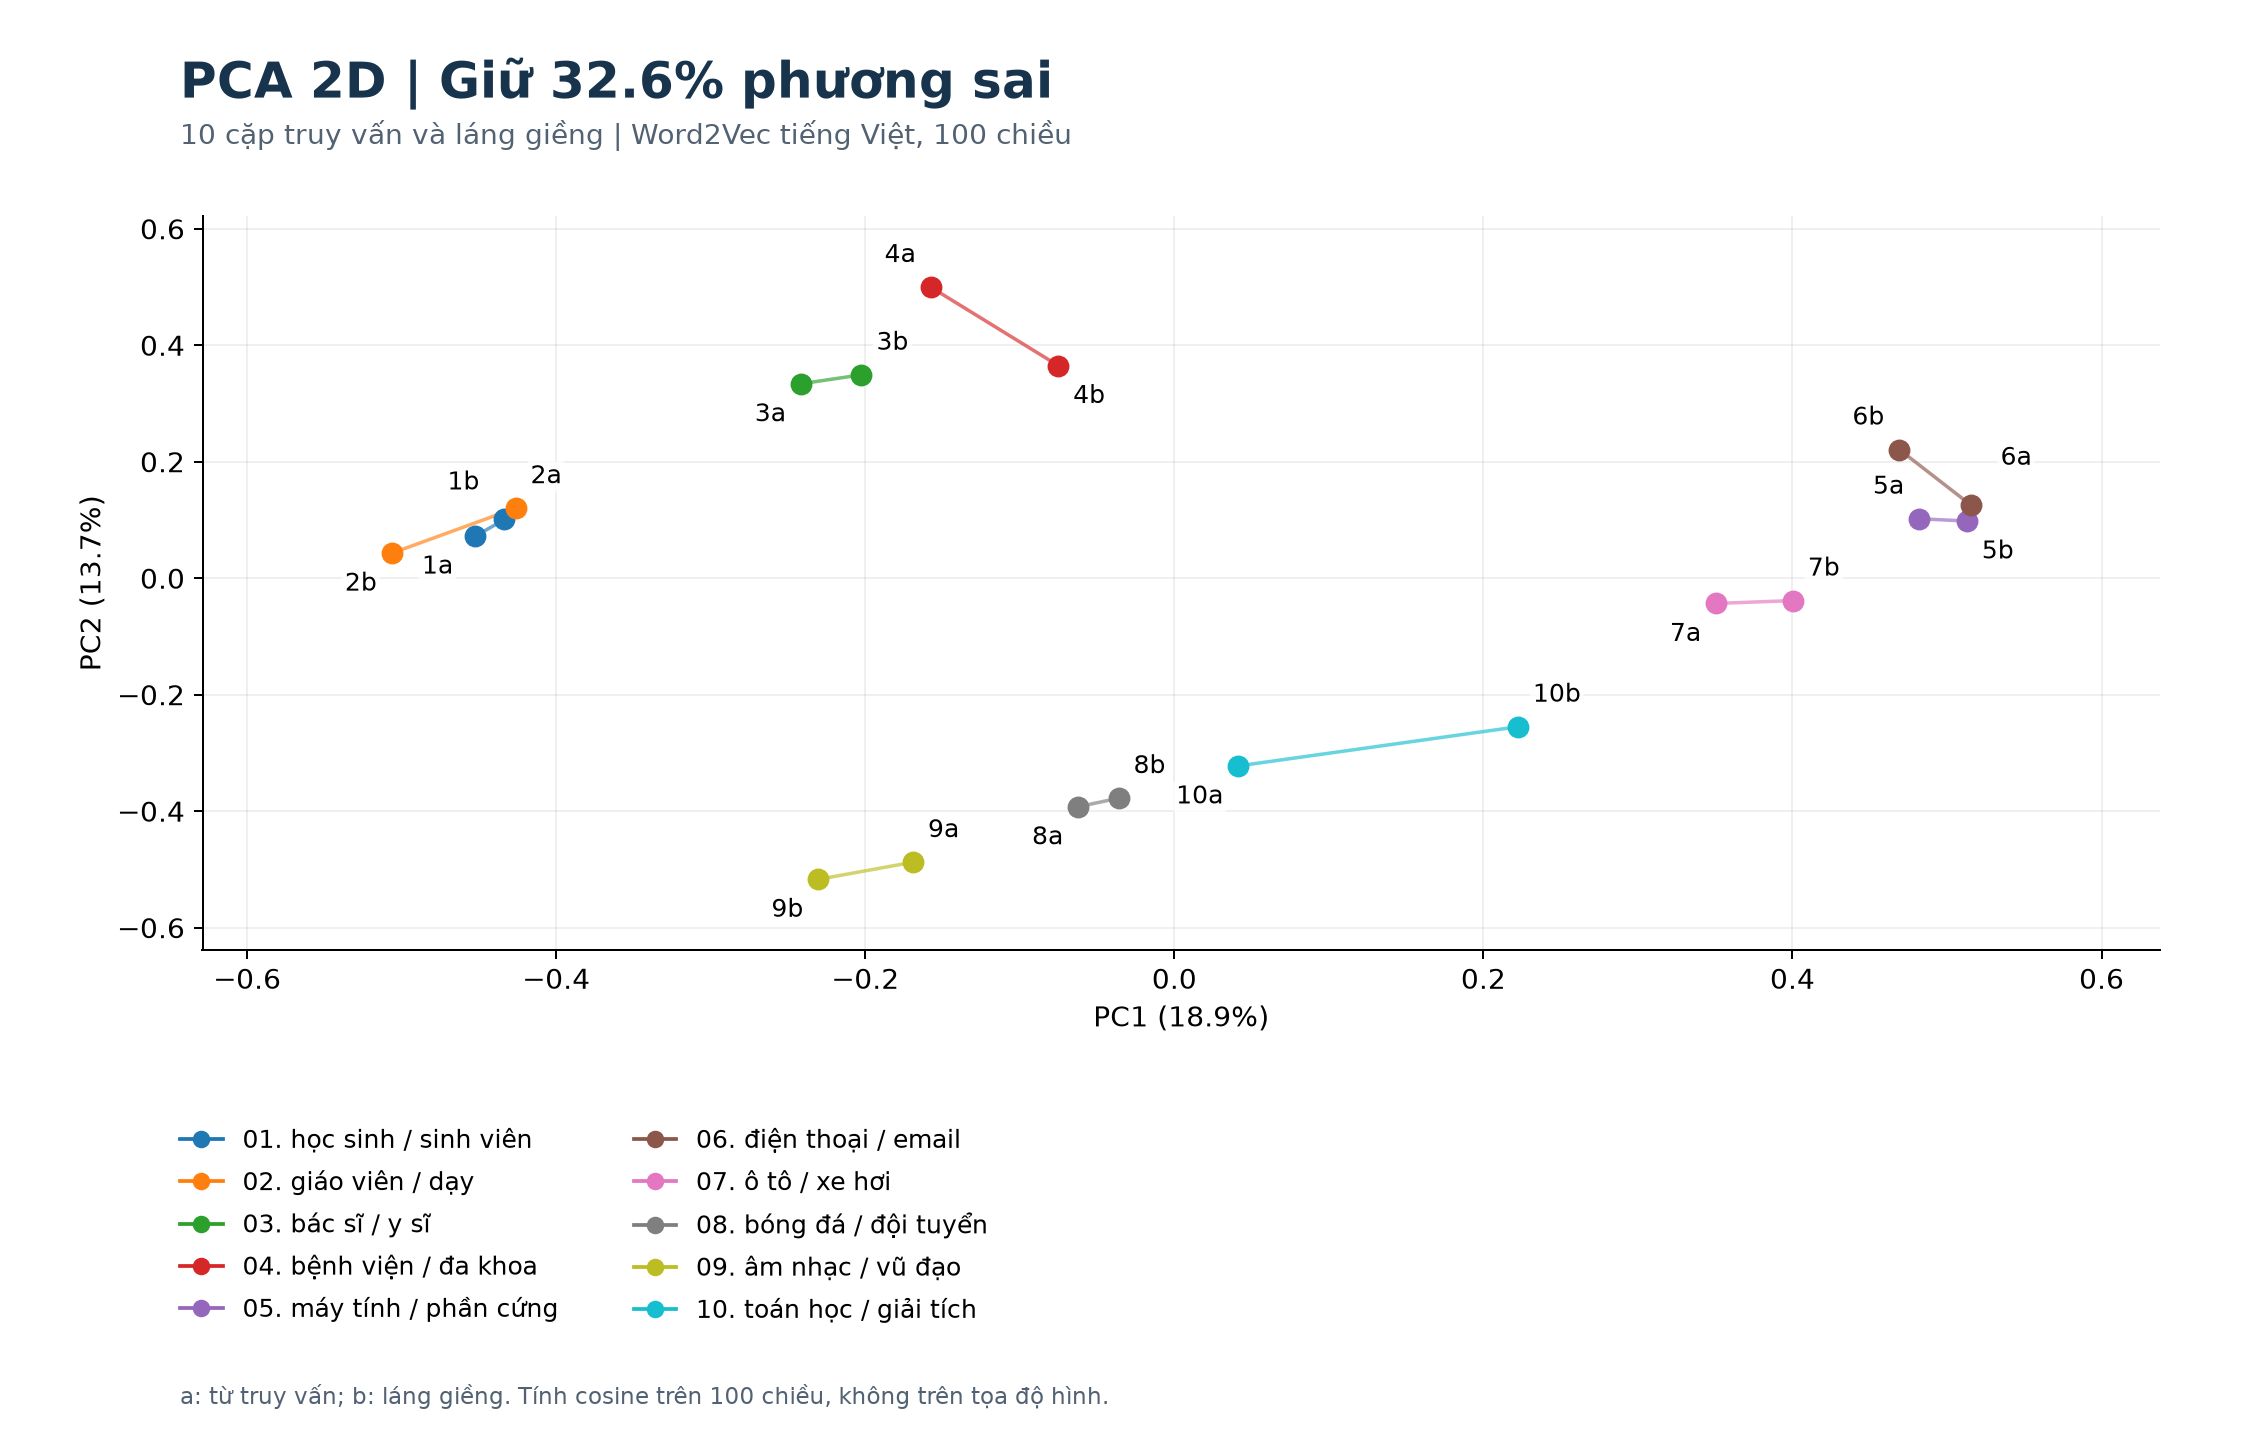

In [12]:
display(Image(filename=str(ROOT / "figures/pca2.png"), width=1000))

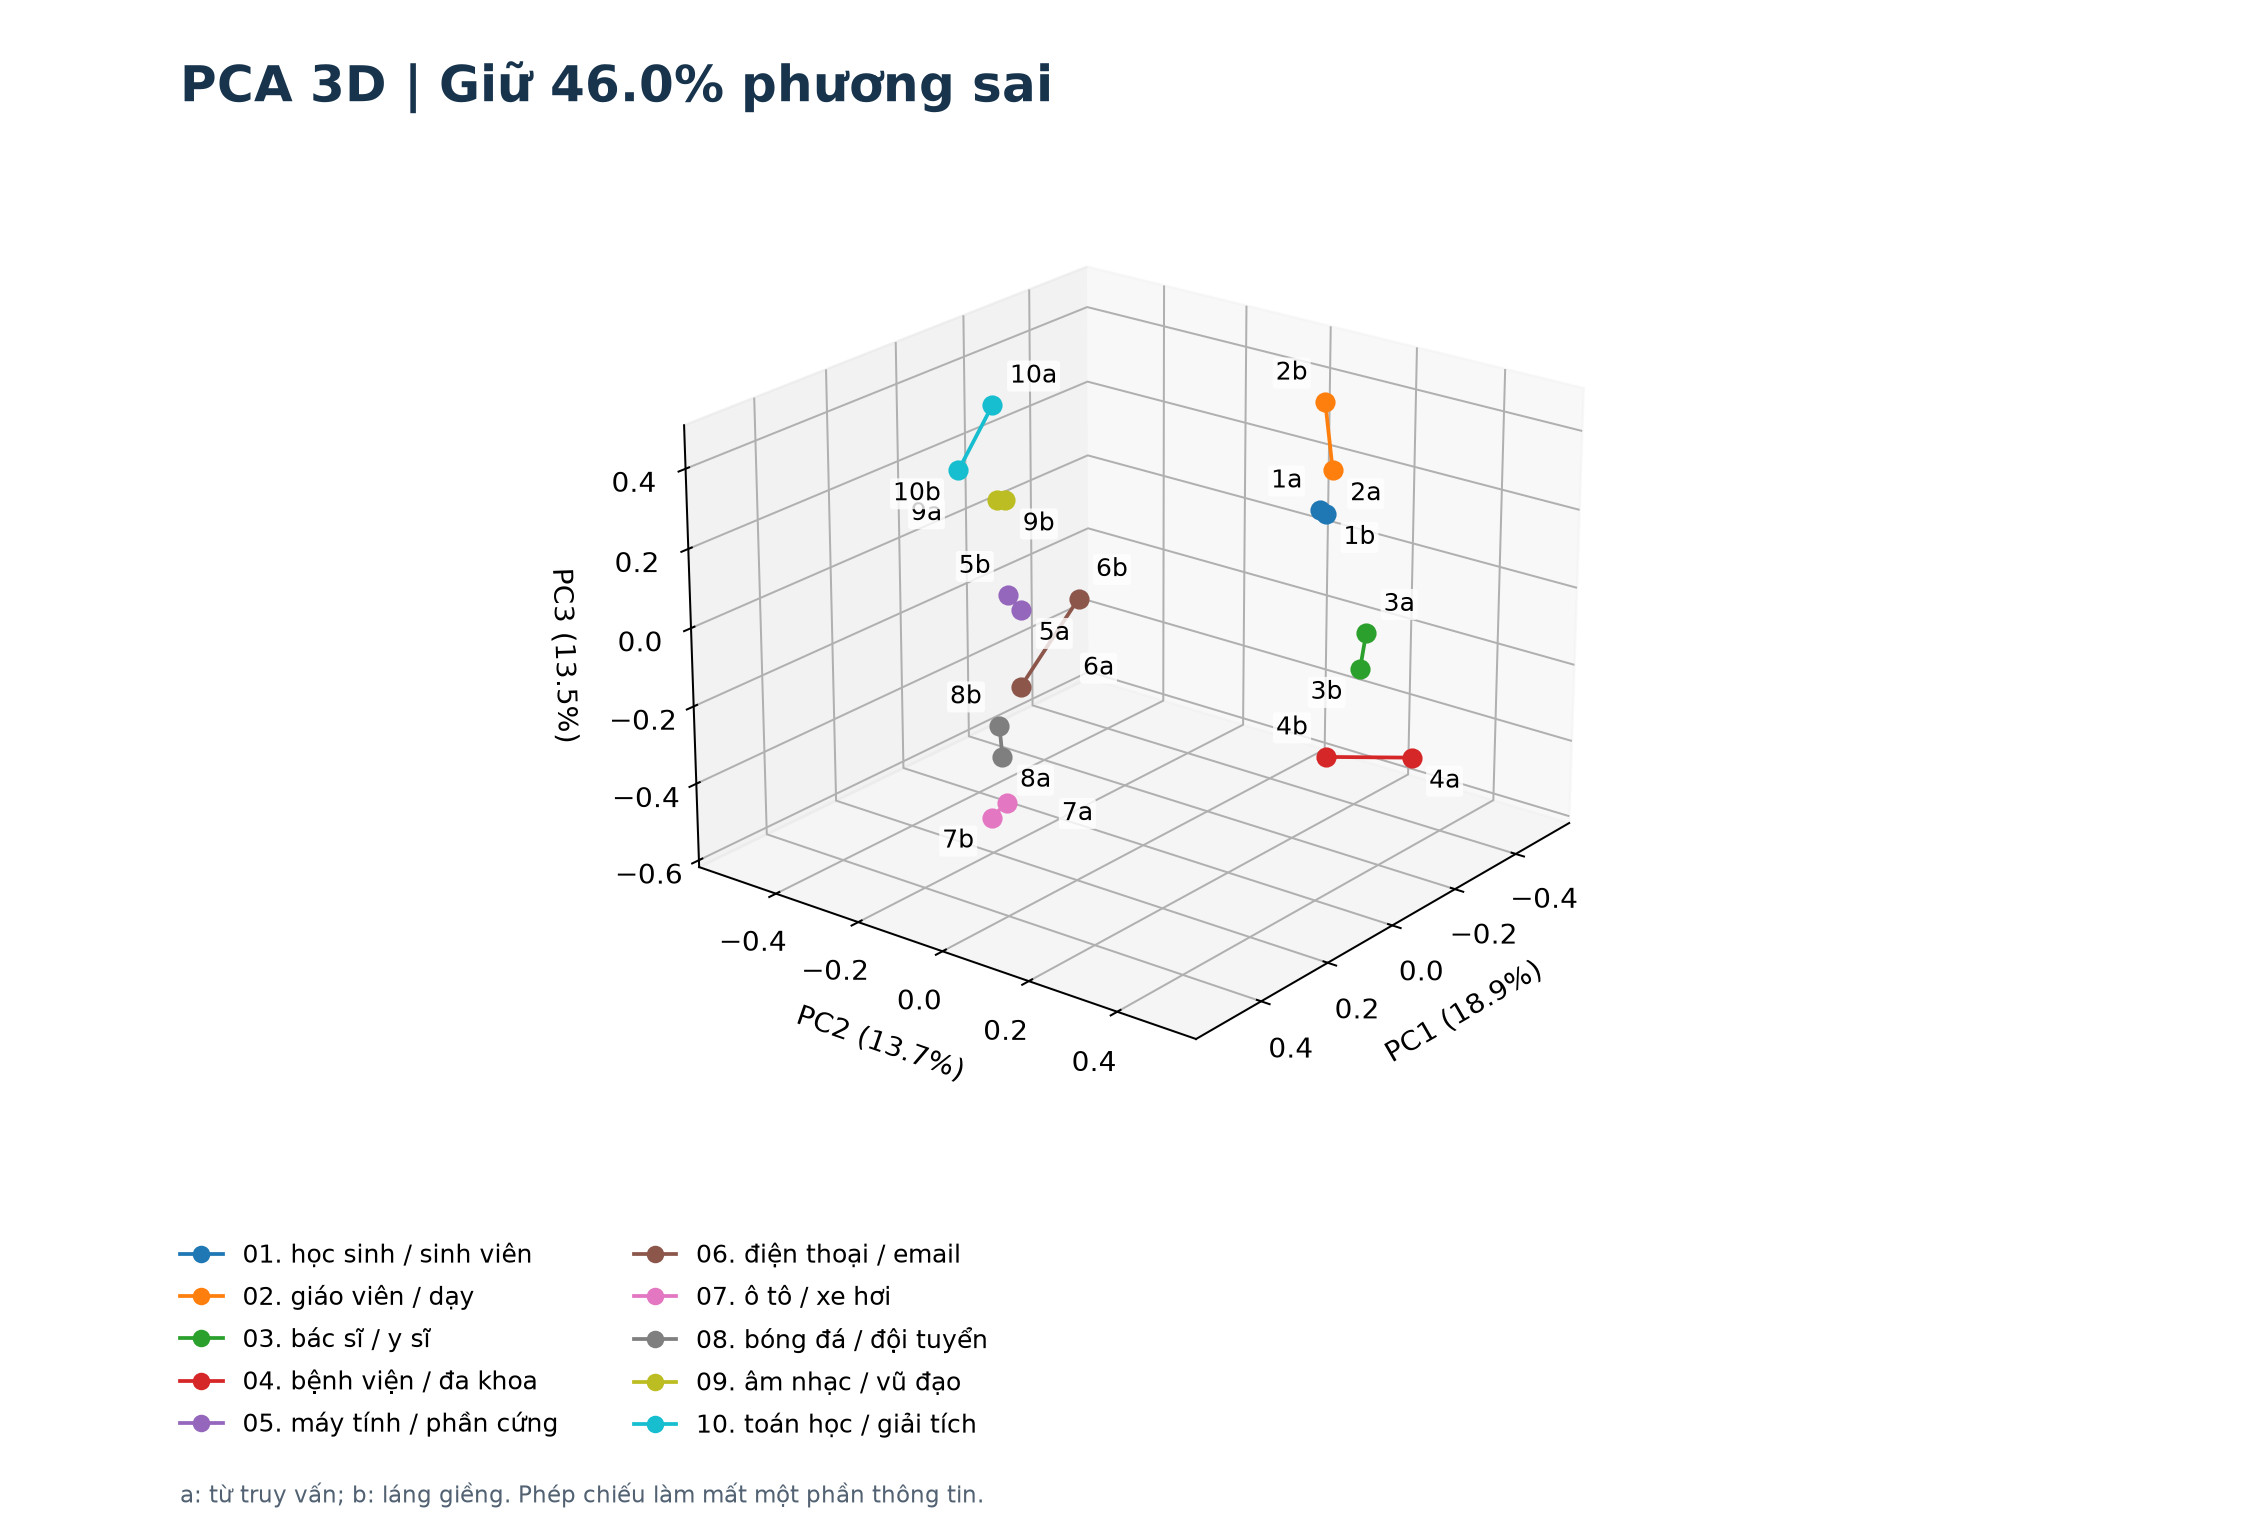

In [13]:
display(Image(filename=str(ROOT / "figures/pca3.png"), width=1000))

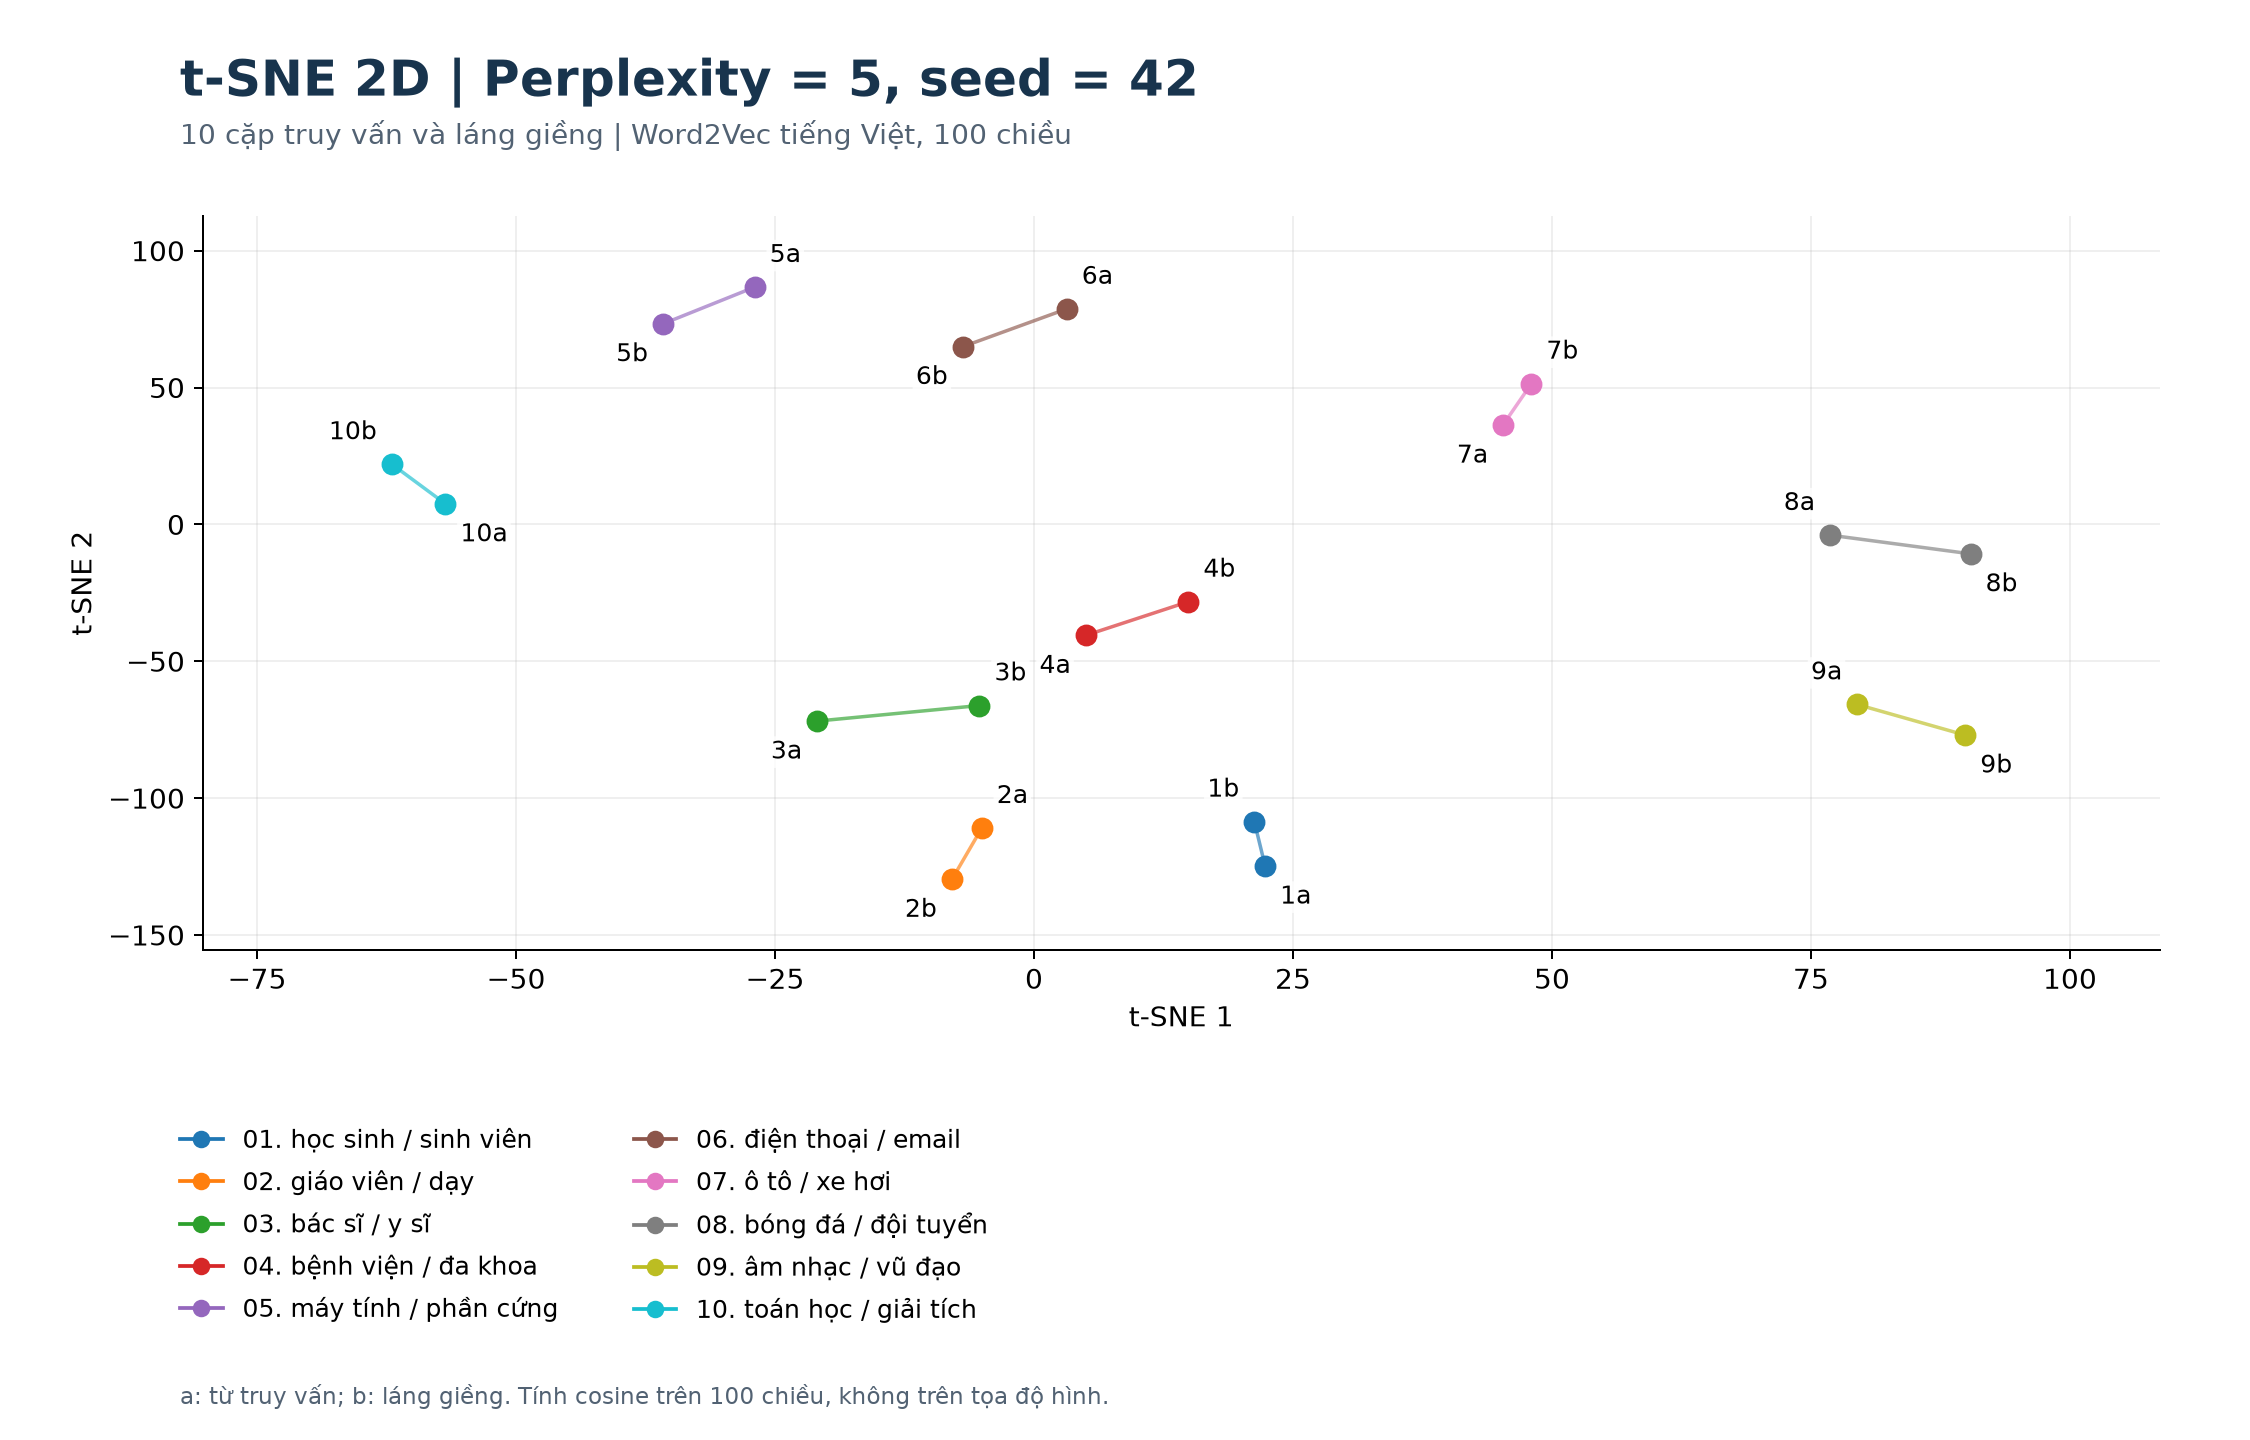

In [14]:
display(Image(filename=str(ROOT / "figures/tsne2.png"), width=1000))

Nhãn `1a`, `1b` tương ứng từ truy vấn và láng giềng của cặp 1; các cặp khác tương tự. Màu và đoạn nối chỉ để theo dõi cặp đã tìm, không phải nhãn cụm do thuật toán học được.

## 6. Kiểm tra kết quả số

Kiểm tra số cặp, kích thước vector, giá trị hữu hạn, cosine tính trực tiếp và tính nhất quán sau khi lưu/nạp mô hình.

In [15]:
assert len(pairs) == 10
assert len({tuple(sorted((p["word1"], p["word2"]))) for p in pairs}) == 10
assert model.wv.vectors.shape == (training_info["vocabulary_size"], 100)
for pair in pairs:
    v, w = model.wv[pair["word1"]], model.wv[pair["word2"]]
    direct = np.dot(v, w) / (np.linalg.norm(v) * np.linalg.norm(w))
    assert np.isclose(direct, pair["cosine"], atol=1e-6)
    assert pair["word1"] != pair["word2"]
for key in ["pca2", "pca3", "tsne2"]:
    assert np.isfinite(reduced[key]).all()
assert np.allclose(reduced["pca2"], reduced["pca3"][:, :2])
reloaded = Word2Vec.load(str(model_path))
assert np.array_equal(reloaded.wv["máy_tính"], model.wv["máy_tính"])
print("Đạt: 10 cặp riêng biệt; cosine khớp; kích thước đúng; tọa độ hữu hạn; mô hình nạp lại nhất quán.")

Đạt: 10 cặp riêng biệt; cosine khớp; kích thước đúng; tọa độ hữu hạn; mô hình nạp lại nhất quán.


## 7. Nhận xét và giới hạn

- Mô hình đã học vector từ corpus tiếng Việt thực tế. Kết quả phụ thuộc nguồn dữ liệu, tách từ, tần suất và cấu hình huấn luyện.
- Tương đồng phân bố có thể là gần nghĩa, cùng loại hoặc liên quan chủ đề. Ví dụ hai từ chỉ nơi chốn và hoạt động thường xuất hiện cùng ngữ cảnh. Không suy ra mọi cặp đều đồng nghĩa (phân biệt ở trang 7 của tài liệu).
- Trong kết quả thực tế: `ô_tô / xe_hơi` là đồng nghĩa; `học_sinh / sinh_viên` cùng nhóm người học. `giáo_viên / dạy` và `bóng_đá / đội_tuyển` chủ yếu liên quan ngữ cảnh, cho thấy hạn chế của cách đo phân bố.
- Các từ ít xuất hiện và lỗi tách từ có thể tạo láng giềng kém hợp lý. Mẫu gồm 2.000 bài đầu không phải mẫu ngẫu nhiên, nên có thiên lệch chủ đề.
- Word2Vec là embedding tĩnh: mỗi token có một vector, chưa tách các nghĩa của từ đa nghĩa.
- Chưa có bộ cặp từ do người gán điểm hoặc tác vụ NLP độc lập để đánh giá; không báo cáo “độ chính xác” từ các cosine này.
- PCA/t-SNE phục vụ trực quan hóa. Tính tương đồng và tìm láng giềng tiếp tục dùng 100 chiều gốc.

**Kết quả bàn giao:** mô hình `.model`, vector `.kv`, bảng 10 cặp, tọa độ 2D/3D, ba hình và metadata. Toàn bộ được tạo từ mã trong notebook.

## 8. Tài liệu tham khảo và ghi công

1. **3. Semantics-WordEmbedding.pdf**, TS. Vương Thị Hải Yến, tài liệu người dùng cung cấp; trang 7, 21, 26, 38, 49-50, 59-61, 69 và 74.
2. [Wikimedia Wikipedia](https://huggingface.co/datasets/wikimedia/wikipedia), `20231101.vi`. Ngữ liệu do cộng đồng Wikipedia đóng góp; thẻ dữ liệu ghi [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/) / [GFDL](https://www.gnu.org/licenses/fdl-1.3.html). URL từng bài và chỉ số hàng có trong `data/wiki_vi_2000.jsonl.gz`; xem lịch sử bài để truy nguyên tác giả. Bản xử lý giữ các điều kiện chia sẻ và ghi công tương ứng.
3. [Gensim Word2Vec](https://radimrehurek.com/gensim/models/word2vec.html).
4. [Pyvi](https://github.com/trungtv/pyvi).
5. [scikit-learn PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [scikit-learn t-SNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html).

Dữ liệu nguồn đã được thay đổi bằng các bước tiền xử lý ở mục 2. Thống kê và SHA-256 được lưu trong metadata để kiểm tra lại.